### 1. Run the nanoreactor 

In [1]:
from arcskin.nanoreactor_run import SMILESPack
from arcskin.nanoreactor_run import XTBNanoReactor


In [2]:
molecules = {"NO": "[N]=O", "O2": "O=O"}
molecules = {"N2":"N#N","O2": "O=O"}
molecules = {"SO2":"O=S=O","NO2":"N(=O)[O]"}
molecules = {"SO3":'O=S(=O)=O',"H2O":"O"}

In [13]:
sp = SMILESPack(molecules.values())
#sp = SMILESPack(["[N]=O","[N]=O"])
cells, charges = sp.run_multiple(
    4, counts=[4, 4], min_dist=2.2
)  # 4 of each molecule, with a minimum distance of 2\AA
cells,charges


([Atoms(symbols='OSO3SO3SO3SO3H2OH2OH2OH2', pbc=False),
  Atoms(symbols='OSO3SO3SO3SO3H2OH2OH2OH2', pbc=False),
  Atoms(symbols='OSO3SO3SO3SO3H2OH2OH2OH2', pbc=False),
  Atoms(symbols='OSO3SO3SO3SO3H2OH2OH2OH2', pbc=False)],
 [0, 0, 0, 0])

In [14]:
xnr = XTBNanoReactor(
    combination=tuple(molecules.values()),
    cells=cells,
    charges=charges,
    temperature=4000,
    time=5,
)
#xnr = XTBNanoReactor(combination = ("[N]=O","[N]=O"),cells=cells, charges=charges, time=5)
xnr.run(location="./example_run/")


In [15]:
xnr.trajectory_locations


['./example_run/seed_0/xtb.trj',
 './example_run/seed_1/xtb.trj',
 './example_run/seed_2/xtb.trj',
 './example_run/seed_3/xtb.trj']

### 2. Analyse the run 

In [16]:
from arcskin.nanoreactor_analysis import AnalyseNanoReactor

anr = AnalyseNanoReactor(skip_step=20, reactants=list(molecules.values()))
#anr = AnalyseNanoReactor(skip_step=20, reactants=["[N]=O","[N]=O"])

anr.read_trajectory(xnr.trajectory_locations, format="xyz")
anr.analyse_trajectories()


calculating with default calculator: aimnet


 16%|█▌        | 8/50 [01:03<05:12,  7.44s/it][13:19:55] UFFTYPER: Unrecognized atom type: S_5+4 (1)
[13:19:55] UFFTYPER: Unrecognized atom type: S_5+4 (1)
  8%|▊         | 4/50 [00:40<06:35,  8.59s/it]

'PointGroupAnalyzer' object has no attribute 'symmops'


 50%|█████     | 25/50 [02:40<02:23,  5.75s/it]

'PointGroupAnalyzer' object has no attribute 'symmops'


...

[13:37:47] UFFTYPER: Unrecognized atom type: S_5+4 (1)
 84%|████████▍ | 42/50 [03:47<00:39,  4.96s/it]

'PointGroupAnalyzer' object has no attribute 'symmops'


 86%|████████▌ | 43/50 [03:53<00:37,  5.35s/it]

'PointGroupAnalyzer' object has no attribute 'symmops'


 50%|█████     | 25/50 [02:00<01:23,  3.36s/it][13:41:12] UFFTYPER: Unrecognized charge state for atom: 1
[13:41:12] UFFTYPER: Unrecognized charge state for atom: 3
 96%|█████████▌| 48/50 [03:10<00:06,  3.26s/it][13:42:20] UFFTYPER: Unrecognized atom type: S_5+4 (1)
[13:42:20] UFFTYPER: Unrecognized atom type: S_5+4 (2)
100%|██████████| 50/50 [03:15<00:00,  3.91s/it]


In [17]:
import pandas as pd

df = pd.DataFrame(anr.unique_smiles_counter).sum(axis=1).sort_values(ascending=False)
df

O=S=O             431.0
O=O               164.0
OO                 88.0
OS(=O)O            51.0
[OH]               49.0
[O]S(=O)O          47.0
O=S1OO1            26.0
[O]OO              23.0
O=S                18.0
[O]O               18.0
[O]SO              15.0
[O]SO[O]           12.0
OO[S@](=O)O        10.0
OO[S@@](=O)O       10.0
[O]S(O)(O)[O]       8.0
[O]O[O]             7.0
[O]S(O)([O])O       7.0
[H][H]              7.0
[O]S1([O])OO1       6.0
OOO                 5.0
[O][O]              3.0
[O]O[S@@](=O)O      2.0
OS1(O)OO1           2.0
[O]O[S@](=O)O       1.0
[O]S([O])O          1.0
[O]S([O])(O)O       1.0
O1OO1               1.0
O1OS21OO2           1.0
dtype: float64

In [18]:
anr.unique_smiles

['O=S=O',
 'OO',
 'OS(=O)O',
 '[OH]',
 '[O]S(=O)O',
 'O=S1OO1',
 '[O]OO',
 'O=S',
 '[O]O',
 '[O]SO',
 '[O]SO[O]',
 'OO[S@@](=O)O',
 '[O]O[O]',
 '[H][H]',
 '[O]S1([O])OO1',
 'OOO',
 '[O][O]',
 'OS1(O)OO1',
 '[O]O[S@](=O)O',
 '[O]S([O])O',
 'O1OO1',
 'O1OS21OO2']

In [19]:
anr.get_sensible_smiles()
possible_paths = anr.get_possible_paths_dict()
possible_paths

[13:48:32] UFFTYPER: Unrecognized atom type: S_5+4 (2)
[13:48:32] UFFTYPER: Unrecognized atom type: S_5+4 (1)
[13:48:32] UFFTYPER: Unrecognized atom type: S_5+4 (1)
[13:48:32] UFFTYPER: Unrecognized atom type: S_5+4 (1)
[13:48:32] UFFTYPER: Unrecognized atom type: S_5+4 (2)
[13:48:34] UFFTYPER: Unrecognized atom type: S_5+4 (1)
[13:48:34] UFFTYPER: Unrecognized atom type: S_5+4 (1)


{0: {'reactants': ['O=S(=O)=O', 'O'],
  'products': ['O1OO1', 'O=S', '[H][H]'],
  'reactants_energies': [-16980.83054728788, -2081.0465410080456],
  'products_energies': [-6136.606861978744,
   -12882.749728476021,
   -31.912600887421164],
  'diff': np.float64(10.607896953737509)},
 1: {'reactants': ['O=S(=O)=O', 'O'],
  'products': ['O1OS21OO2', '[H][H]'],
  'reactants_energies': [-16980.83054728788, -2081.0465410080456],
  'products_energies': [-19022.41170231382, -31.912600887421164],
  'diff': np.float64(7.552785094681894)},
 2: {'reactants': ['O=S(=O)=O', 'O'],
  'products': ['O=S', 'OOO'],
  'reactants_energies': [-16980.83054728788, -2081.0465410080456],
  'products_energies': [-12882.749728476021, -6172.64561540416],
  'diff': np.float64(6.481744415745197)},
 3: {'reactants': ['O=S(=O)=O', 'O'],
  'products': ['O=S', '[H][H]', '[O]O[O]'],
  'reactants_energies': [-16980.83054728788, -2081.0465410080456],
  'products_energies': [-12882.749728476021,
   -31.912600887421164,
   -6

### 3. Calculate the Energy barriers with NEB 

In [1]:
from monty.serialization import loadfn

possible_paths = loadfn("possible_paths.json")

In [2]:
from arcskin.make_neb_endpoints import make_endpoints

reaction_endpoints = {}
for k,v in possible_paths.items():
    try:
        reactants, products = make_endpoints(v["reactants"],v["products"],shift=1.5)
        reaction_endpoints[k] = {
            "reactants":reactants,
            "products":products,
            "overall":possible_paths[k]
                                 }
    except Exception:
        print(f"{k} failed")
        pass

O=S(=O)=O + O -> O1OO1 + O=S + [H][H] | form: ['O0-O2', 'O0-O4', 'O2-O4', 'H5-H6']  break: ['O0-S1', 'S1-O2', 'O4-H5', 'O4-H6']


[14:17:54] UFFTYPER: Unrecognized atom type: S_5+4 (2)


O=S(=O)=O + O -> O1OS21OO2 + [H][H] | form: ['O0-O2', 'O3-O4', 'S1-O4', 'H5-H6']  break: ['O4-H5', 'O4-H6']
O=S(=O)=O + O -> O=S + OOO | form: ['O0-O2', 'O0-O4', 'O2-H5']  break: ['O0-S1', 'S1-O2', 'O4-H5']
O=S(=O)=O + O -> O=S + [H][H] + [O]O[O] | form: ['H5-H6', 'O0-O2', 'O0-O4']  break: ['O0-S1', 'S1-O2', 'O4-H5', 'O4-H6']
O=S(=O)=O + O -> O=S + [OH] + [O]O | form: ['O0-O2', 'O0-H5']  break: ['O0-S1', 'S1-O2', 'O4-H5']
O=S(=O)=O + O -> O=S=O + OO | form: ['O0-O4', 'O0-H5']  break: ['O0-S1', 'O4-H5']
O=S(=O)=O + O -> O=S=O + [H][H] + [O][O] | form: ['H5-H6', 'O0-O4']  break: ['O0-S1', 'O4-H5', 'O4-H6']
O=S(=O)=O + O -> O=S=O + [OH] + [OH] | form: ['O0-H5']  break: ['O0-S1', 'O4-H5']
O=S(=O)=O + O -> OO[S@@](=O)O | form: ['O0-O4', 'O2-H5']  break: ['O4-H5']
O=S(=O)=O + O -> OS1(O)OO1 | form: ['S1-O4', 'O0-O2', 'O3-H5']  break: ['O4-H5']


[14:17:55] UFFTYPER: Unrecognized atom type: S_5+4 (1)
[14:17:55] UFFTYPER: Unrecognized atom type: S_5+4 (1)


O=S(=O)=O + O -> [H][H] + [O]S1([O])OO1 | form: ['H5-H6', 'S1-O4', 'O0-O2']  break: ['O4-H5', 'O4-H6']
O=S(=O)=O + O -> [OH] + [O]S(=O)O | form: ['O0-H5']  break: ['O4-H5']
O=S(=O)=O + O -> [O]O + [O]SO | form: ['O0-O4', 'O2-H5']  break: ['O0-S1', 'O4-H5']


In [3]:
from arcskin.run_neb import run_all

results = run_all(reaction_endpoints,n_images=3,fmax=0.1)

Warp 1.18.0 initialized:
   CUDA not enabled in this build
   Devices:
     "cpu"      : "arm"
   Kernel cache:
     /Users/badw/Library/Caches/warp/1.18.0
running with aimnet


In [4]:
results


,Ea,dE,reactants,products,reactants_energies,products_energies,diff,images,sane
11,0.0,-0.00287,"[O=S(=O)=O, O]","[[OH], [O]S(=O)O]","[-16980.830547, -2081.046541]","[-2059.431395, -16995.138381]",7.307312,"[Atoms(symbols='OSO3H2', pbc=False, calculator...",False
5,2.03462,2.03462,"[O=S(=O)=O, O]","[O=S=O, OO]","[-16980.830547, -2081.046541]","[-14933.345807, -4126.563266]",1.968015,"[Atoms(symbols='OSO3H2', pbc=False, calculator...",True
12,2.536098,2.358787,"[O=S(=O)=O, O]","[[O]O, [O]SO]","[-16980.830547, -2081.046541]","[-4106.682937, -14947.51803]",7.676122,"[Atoms(symbols='OSO3H2', pbc=False, calculator...",True
8,2.598036,2.489344,"[O=S(=O)=O, O]",[OO[S@@](=O)O],"[-16980.830547, -2081.046541]",[-19059.953236],1.923853,"[Atoms(symbols='OSO3H2', pbc=False, calculator...",True
7,2.891236,1.908003,"[O=S(=O)=O, O]","[O=S=O, [OH], [OH]]","[-16980.830547, -2081.046541]","[-14933.345807, -2059.431395, -2059.431395]",9.668492,"[Atoms(symbols='OSO3H2', pbc=False, calculator...",True
9,3.616244,3.212105,"[O=S(=O)=O, O]",[OS1(O)OO1],"[-16980.830547, -2081.046541]",[-19058.836583],3.040506,"[Atoms(symbols='OSO3H2', pbc=False, calculator...",True
4,4.427411,4.389671,"[O=S(=O)=O, O]","[O=S, [OH], [O]O]","[-16980.830547, -2081.046541]","[-12882.749728, -2059.431395, -4106.682937]",13.013028,"[Atoms(symbols='OSO3H2', pbc=False, calculator...",True
10,4.50954,4.478165,"[O=S(=O)=O, O]","[[H][H], [O]S1([O])OO1]","[-16980.830547, -2081.046541]","[-31.912601, -19025.977721]",3.986766,"[Atoms(symbols='OSO3H2', pbc=False, calculator...",True
6,5.161035,5.060964,"[O=S(=O)=O, O]","[O=S=O, [H][H], [O][O]]","[-16980.830547, -2081.046541]","[-14933.345807, -31.912601, -4091.617422]",5.001258,"[Atoms(symbols='OSO3H2', pbc=False, calculator...",True
3,6.351859,6.351859,"[O=S(=O)=O, O]","[O=S, [H][H], [O]O[O]]","[-16980.830547, -2081.046541]","[-12882.749728, -31.912601, -6137.613135]",9.601623,"[Atoms(symbols='OSO3H2', pbc=False, calculator...",True


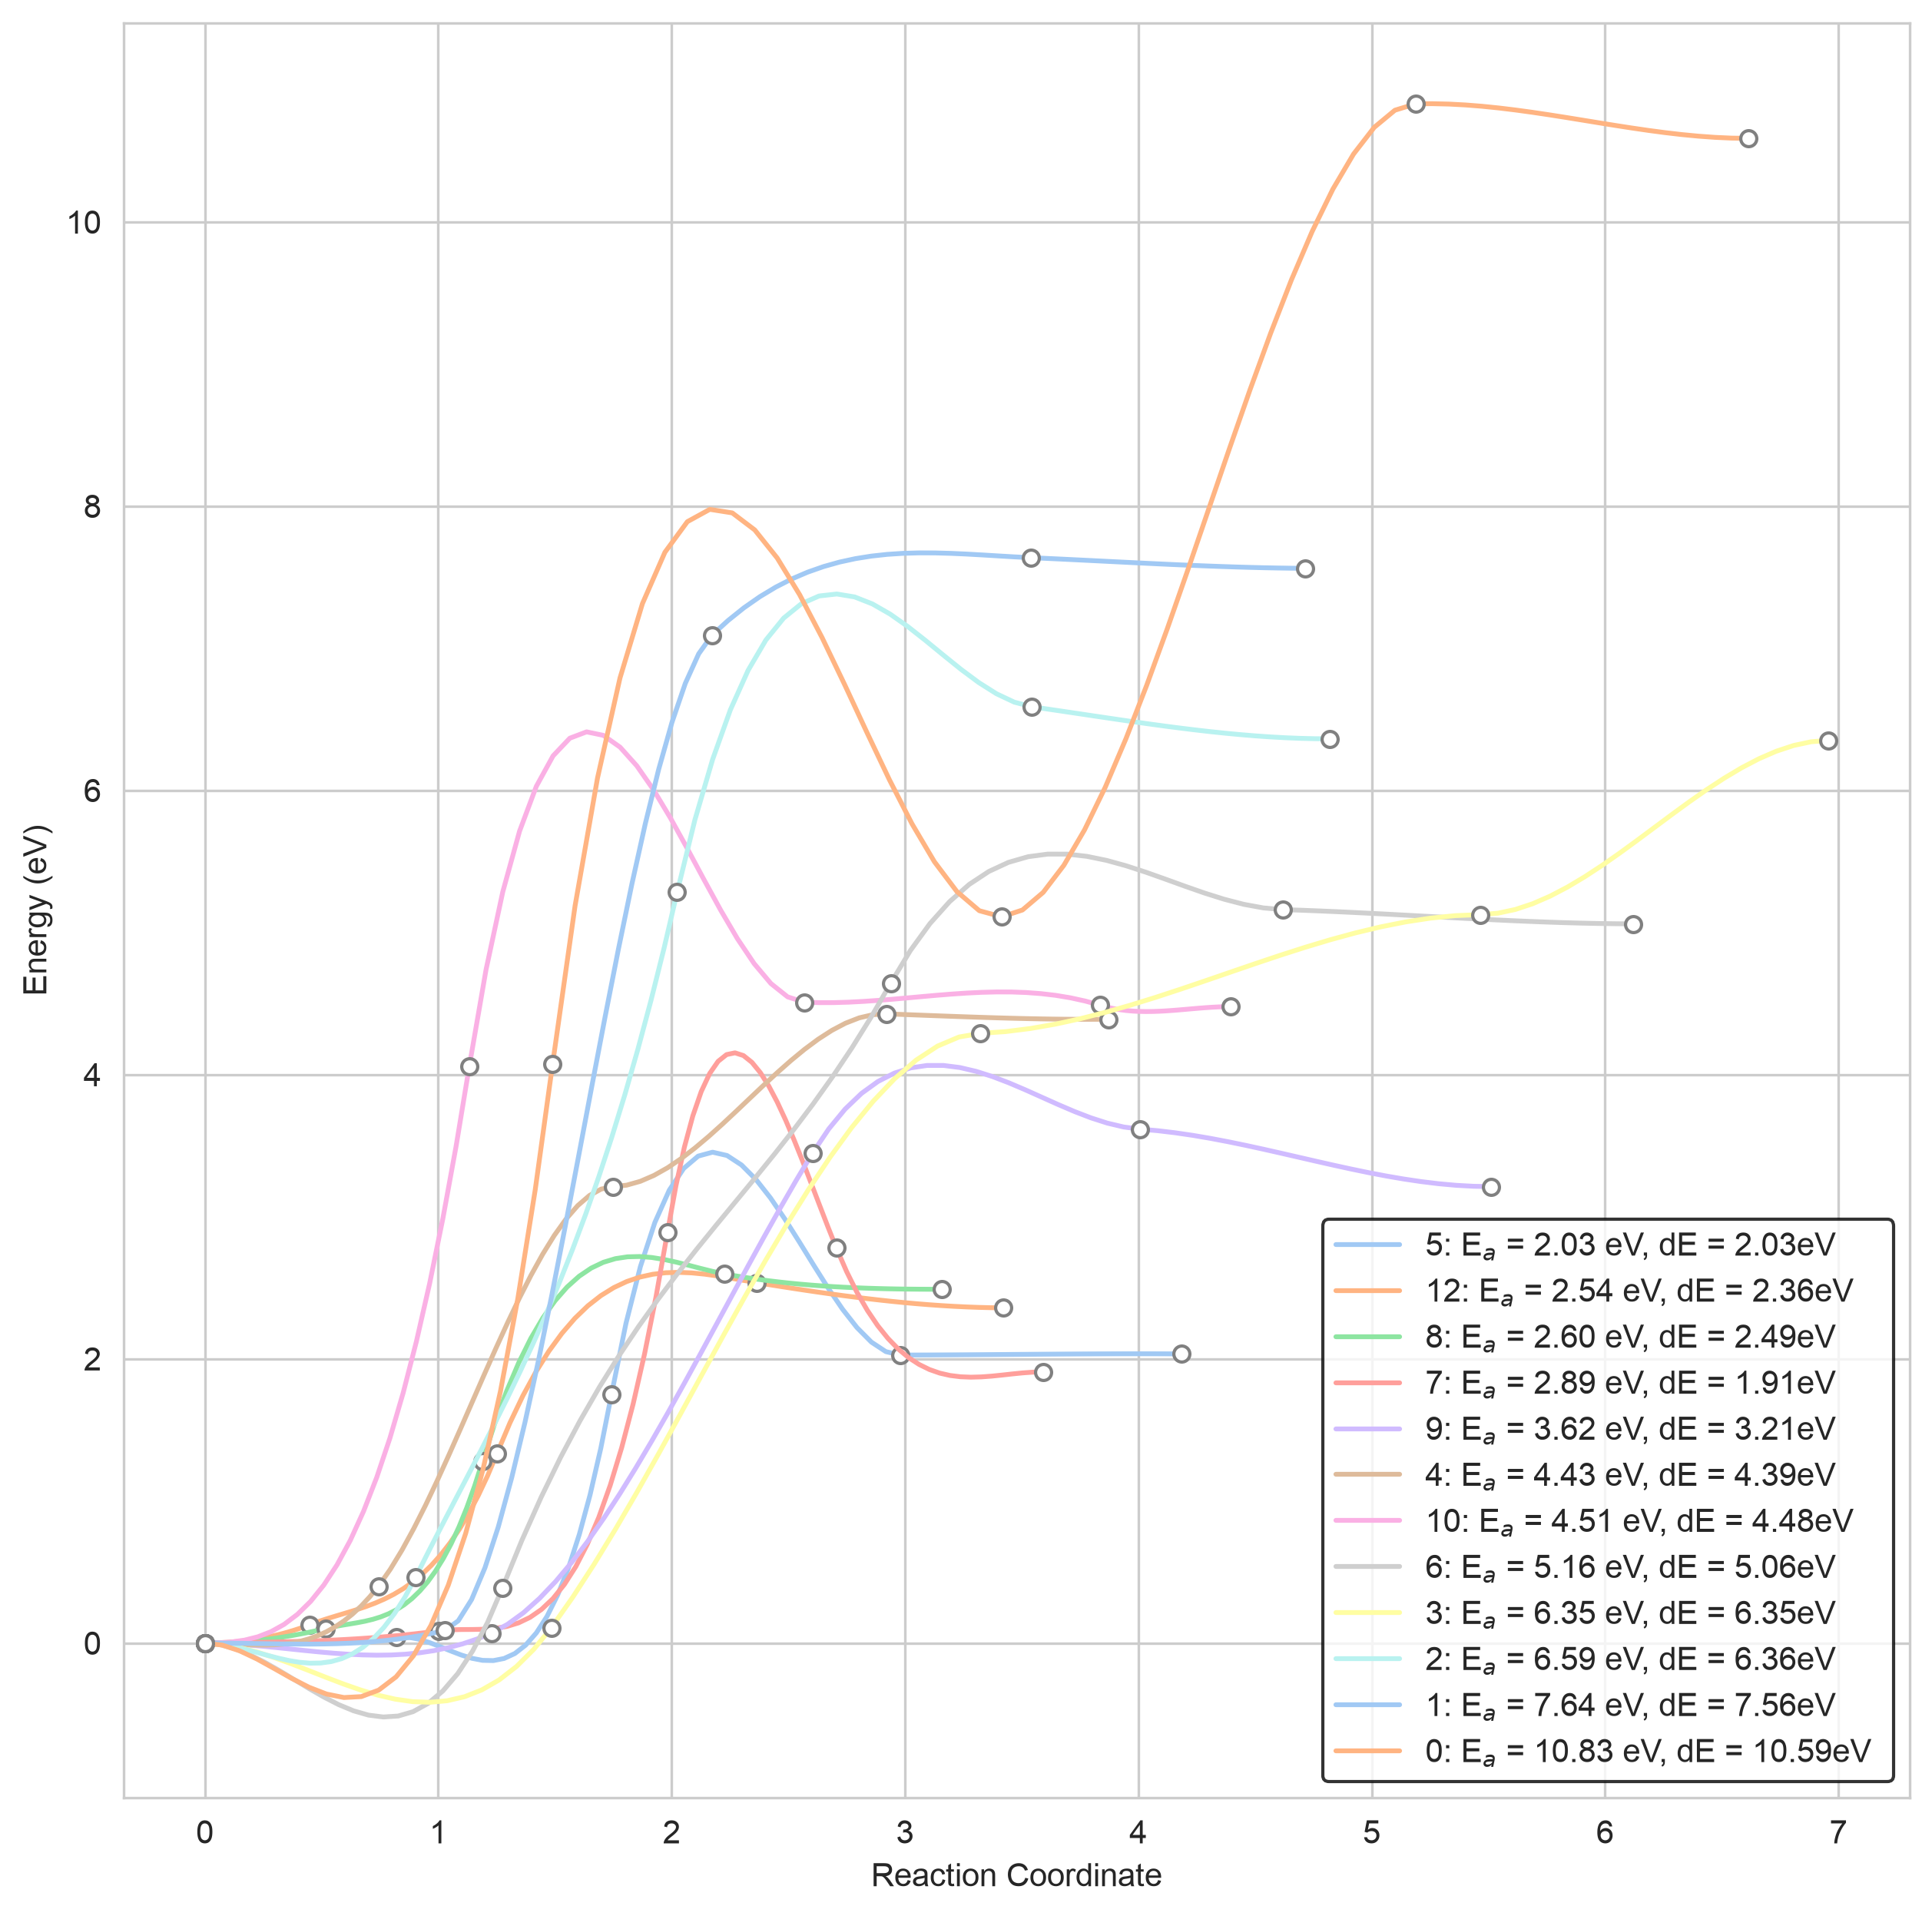

In [6]:
import seaborn as sns 
import matplotlib.pyplot as plt 
from ase.mep import NEBTools
from ase.utils import forcecurve
import seaborn as sns 
import matplotlib.pyplot as plt 
from ase.mep import NEBTools
from ase.utils import forcecurve
import collections 

sns.set_style('whitegrid')
sns.set_palette('pastel')

def plot_nebruns(image_dict,ax,chosen=None,sane=True,**kws):
    for k,v in image_dict.items():
        if chosen: 
            if chosen == k:
                print(k,v)
                fit = forcecurve.fit_images(v["images"])
                Ef = fit[1].max()
                ax.plot(fit[2],fit[3],label=f'{k}: E$_a$ = {Ef :.2F} eV, dE = {v["dE"]:.2F}eV ')
                ax.plot(fit[0],fit[1],**kws)
        else:
            if v["sane"]:
                fit = forcecurve.fit_images(v["images"])
                Ef = fit[1].max()
                ax.plot(fit[2],fit[3],label=f'{k}: E$_a$ = {Ef :.2F} eV, dE = {v["dE"]:.2F}eV ')
                ax.plot(fit[0],fit[1],**kws)

kws = {'marker':'o',
       'linestyle':'None',
       'color':'grey',
       'markerfacecolor':'white',
       'markersize':5}

fig,ax = plt.subplots(ncols=1,nrows=1,figsize=(10,10),dpi=300,sharey=True,sharex=True)
plot_nebruns(image_dict=results.T,ax=ax,**kws)
ax.set_ylabel('Energy (eV)')
ax.set_xlabel('Reaction Coordinate')
ax.legend(edgecolor="black")

In [10]:
results.T

,11,5,12,8,7,9,4,10,6,3,2,1,0
Ea,0.0,2.03462,2.536098,2.598036,2.891236,3.616244,4.427411,4.50954,5.161035,6.351859,6.588105,7.637605,10.83118
dE,-0.00287,2.03462,2.358787,2.489344,1.908003,3.212105,4.389671,4.478165,5.060964,6.351859,6.363002,7.562753,10.588478
reactants,"[O=S(=O)=O, O]","[O=S(=O)=O, O]","[O=S(=O)=O, O]","[O=S(=O)=O, O]","[O=S(=O)=O, O]","[O=S(=O)=O, O]","[O=S(=O)=O, O]","[O=S(=O)=O, O]","[O=S(=O)=O, O]","[O=S(=O)=O, O]","[O=S(=O)=O, O]","[O=S(=O)=O, O]","[O=S(=O)=O, O]"
products,"[[OH], [O]S(=O)O]","[O=S=O, OO]","[[O]O, [O]SO]",[OO[S@@](=O)O],"[O=S=O, [OH], [OH]]",[OS1(O)OO1],"[O=S, [OH], [O]O]","[[H][H], [O]S1([O])OO1]","[O=S=O, [H][H], [O][O]]","[O=S, [H][H], [O]O[O]]","[O=S, OOO]","[O1OS21OO2, [H][H]]","[O1OO1, O=S, [H][H]]"
reactants_energies,"[-16980.830547, -2081.046541]","[-16980.830547, -2081.046541]","[-16980.830547, -2081.046541]","[-16980.830547, -2081.046541]","[-16980.830547, -2081.046541]","[-16980.830547, -2081.046541]","[-16980.830547, -2081.046541]","[-16980.830547, -2081.046541]","[-16980.830547, -2081.046541]","[-16980.830547, -2081.046541]","[-16980.830547, -2081.046541]","[-16980.830547, -2081.046541]","[-16980.830547, -2081.046541]"
products_energies,"[-2059.431395, -16995.138381]","[-14933.345807, -4126.563266]","[-4106.682937, -14947.51803]",[-19059.953236],"[-14933.345807, -2059.431395, -2059.431395]",[-19058.836583],"[-12882.749728, -2059.431395, -4106.682937]","[-31.912601, -19025.977721]","[-14933.345807, -31.912601, -4091.617422]","[-12882.749728, -31.912601, -6137.613135]","[-12882.749728, -6172.645615]","[-19022.411702, -31.912601]","[-6136.606862, -12882.749728, -31.912601]"
diff,7.307312,1.968015,7.676122,1.923853,9.668492,3.040506,13.013028,3.986766,5.001258,9.601623,6.481744,7.552785,10.607897
images,"[Atoms(symbols='OSO3H2', pbc=False, calculator...","[Atoms(symbols='OSO3H2', pbc=False, calculator...","[Atoms(symbols='OSO3H2', pbc=False, calculator...","[Atoms(symbols='OSO3H2', pbc=False, calculator...","[Atoms(symbols='OSO3H2', pbc=False, calculator...","[Atoms(symbols='OSO3H2', pbc=False, calculator...","[Atoms(symbols='OSO3H2', pbc=False, calculator...","[Atoms(symbols='OSO3H2', pbc=False, calculator...","[Atoms(symbols='OSO3H2', pbc=False, calculator...","[Atoms(symbols='OSO3H2', pbc=False, calculator...","[Atoms(symbols='OSO3H2', pbc=False, calculator...","[Atoms(symbols='OSO3H2', pbc=False, calculator...","[Atoms(symbols='OSO3H2', pbc=False, calculator..."
sane,False,True,True,True,True,True,True,True,True,True,True,True,True


In [5]:
from ase.visualize import view 

view(results["images"][11],viewer="ngl")

KeyError: 11